# Podstawy sztucznej inteligencji: przestrzeń stanów, BFS, DFS, heurystyki i A*

Ten notatnik jest przeznaczony do pracy w **Google Colab**.

## Cele
Po wykonaniu notatnika student powinien:
- rozumieć pojęcie **przestrzeni stanów**,
- umieć reprezentować problem jako graf,
- rozumieć działanie **BFS** i **DFS**,
- wiedzieć, czym jest **heurystyka**,
- rozumieć funkcję $f(n) = g(n) + h(n)$ używaną w algorytmie **A\***,
- potrafić porównać BFS, DFS i A* pod względem:
  - kompletności,
  - optymalności,
  - liczby odwiedzonych stanów,
  - wykorzystania informacji o celu.


## 1. Problem jako przestrzeń stanów

W wielu klasycznych problemach AI nie pytamy od razu:

> „Jak wygląda rozwiązanie?”

Zamiast tego definiujemy:

1. **stan początkowy**,
2. **zbiór możliwych stanów**,
3. **operatory / akcje**, które zmieniają stan,
4. **test celu**,
5. opcjonalnie **koszt przejścia**.

Przykłady:
- znalezienie drogi na mapie,
- układanka 8-puzzle,
- szachy,
- planowanie działań robota,
- rozwiązanie problemu logicznego.

W tym notatniku wykorzystamy prosty świat w postaci **siatki 2D**.

- `0` – pole dostępne,
- `1` – przeszkoda,
- `S` – start,
- `G` – cel.


In [59]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import deque
import heapq
import math

COST = {
    '.': 1,
    'P': 3,  # Piasek
    'B': 5,  # Bagno
    'S': 1,
    'G': 1,
    '#': float('inf')
}

MAPA = [
    "..............",
    ".......P.P....",
    "......PPBPP...",
    "......#BBBB#..",
    "..S..P#BBBBP..",
    "....PP#BBBB#..",
    ".....P#PPPP#..",
    "......PB...#G.",
    ".......####...",
    "..............",
]

start = (1, 5)
goal = (7, 12)

grid = [list(wiersz) for wiersz in MAPA]

rows = len(grid)
cols = len(grid[0])

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

Rozmiar planszy: 10 x 14
Start: (1, 5)
Cel: (7, 12)



### Reprezentacja stanu

Stanem będzie para:

```python
(wiersz, kolumna)
```

Np. `(2, 4)` oznacza komórkę w trzecim wierszu i piątej kolumnie.

Dozwolone akcje:
- góra,
- dół,
- lewo,
- prawo.

Nie wolno:
- wyjść poza planszę,
- wejść na przeszkodę.


In [60]:

def get_neighbors(state):
    r, c = state

    moves = [
        (0, -1),  # lewo
        (1, 0),   # dół
        (-1, 0),  # góra
        (0, 1),   # prawo

        (-1,-1), #lewo góra
        (-1, 1), #prawo góra
        (1, 1), #prawo dół
        (1,-1), #lewo dół
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] != '#':

                if dr != 0 and dc != 0:
                    if grid[r + dr][c] == '#' and grid[r][c + dc] == '#':
                        continue
                neighbors.append((nr, nc))

    return neighbors


print("Sąsiedzi startu:", get_neighbors(start))


Sąsiedzi startu: [(1, 4), (2, 5), (0, 5), (1, 6), (0, 4), (0, 6), (2, 6), (2, 4)]



## 2. Wizualizacja problemu


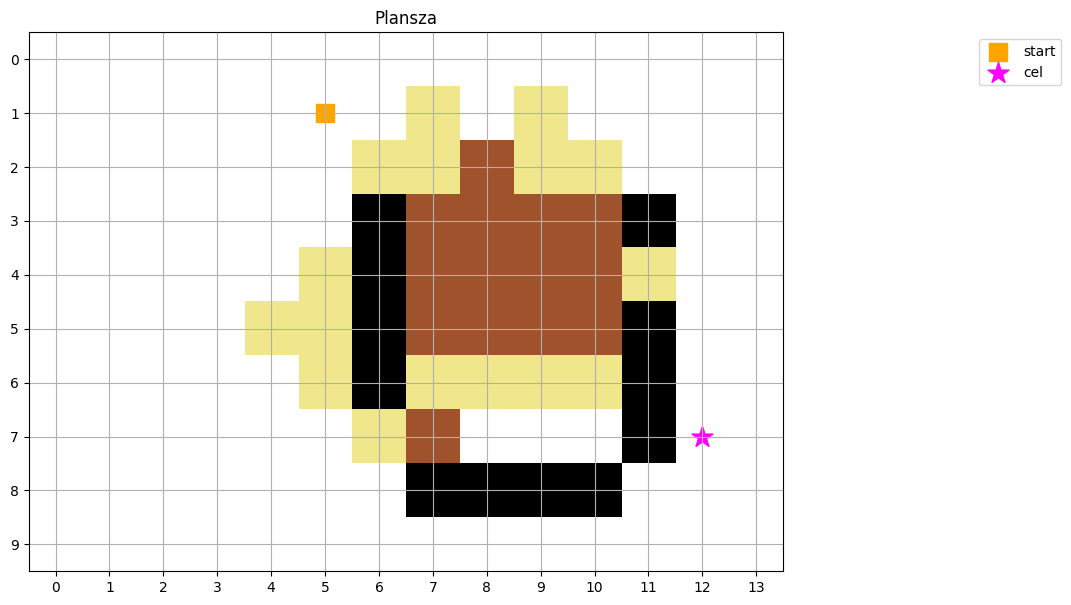

In [61]:
def draw_grid(path=None, visited=None, title="Plansza"):

    color_map_vals = {'.': 0, 'P': 1, 'B': 2, '#': 3, 'S': 0, 'G': 0}
    img = [[color_map_vals.get(cell, 0) for cell in row] for row in grid]

    #Kolory
    cmap = ListedColormap(['white', 'khaki', 'sienna', 'black'])

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap=cmap, origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        # kolor punktu = kolejność odwiedzin (ciemny – wcześnie, jasny – późno)
        sc = plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                         s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o", linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s", color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*", color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()


draw_grid()


# 3. BFS — Breadth-First Search

BFS przeszukuje graf **warstwami**.

Najpierw:
- start,
- potem stany odległe o 1 krok,
- potem o 2 kroki,
- potem o 3 kroki,
- itd.

BFS wykorzystuje **kolejkę FIFO**.

### Ważna własność

Jeśli wszystkie przejścia mają taki sam koszt, BFS znajduje **najkrótszą ścieżkę**.

Schemat:

```text
kolejka = [start]

dopóki kolejka nie jest pusta:
    pobierz pierwszy element
    jeżeli to cel:
        zakończ
    dodaj nieodwiedzonych sąsiadów na koniec kolejki
```


BFS - długość ścieżki: 9
BFS - odwiedzone stany: 119
BFS - ścieżka: [(1, 5), (1, 6), (1, 7), (1, 8), (2, 9), (3, 10), (4, 11), (5, 12), (6, 12), (7, 12)]


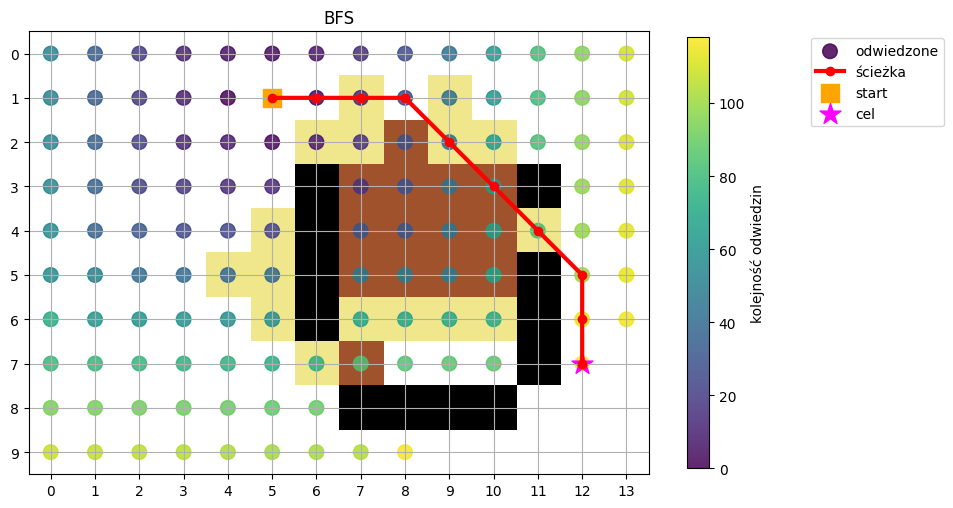

In [62]:

def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

print("BFS - długość ścieżki:", len(bfs_path) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited))
print("BFS - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS")

#dla skosu - sqrt(2)
def calculate_path_cost(path):
    if not path or len(path) < 2:
        return 0.0 if path else float("inf")

    total = 0.0
    for current, neighbor in zip(path, path[1:]):
        r1, c1 = current
        r2, c2 = neighbor
        cell_cost = COST[grid[r2][c2]]
        diagonal_factor = math.sqrt(2) if r1 != r2 and c1 != c2 else 1.0
        total += cell_cost * diagonal_factor
    return total



### Pytania

1. Dlaczego BFS używa kolejki, a nie stosu?
2. Dlaczego BFS znajduje najkrótszą ścieżkę przy jednakowych kosztach przejść?
3. Co się stanie z pamięcią BFS, gdy przestrzeń stanów będzie bardzo duża?


# 4. DFS — Depth-First Search

DFS wybiera jedną gałąź i idzie **jak najgłębiej**.

Wykorzystuje:
- stos,
- albo rekurencję.

DFS nie gwarantuje najkrótszej ścieżki.

W wersji **bez** zapamiętywania odwiedzonych stanów DFS zużywa znacznie mniej pamięci niż BFS – pamięta tylko bieżącą gałąź. W naszej implementacji (ze zbiorem `visited`) oba algorytmy mogą w najgorszym razie pamiętać wszystkie stany.

DFS - długość ścieżki: 21
DFS - odwiedzone stany: 22
DFS - ścieżka: [(1, 5), (2, 4), (3, 3), (4, 2), (5, 1), (6, 0), (7, 1), (8, 0), (9, 1), (8, 2), (9, 3), (8, 4), (9, 5), (8, 6), (9, 7), (9, 8), (9, 9), (9, 10), (8, 11), (9, 12), (8, 13), (7, 12)]


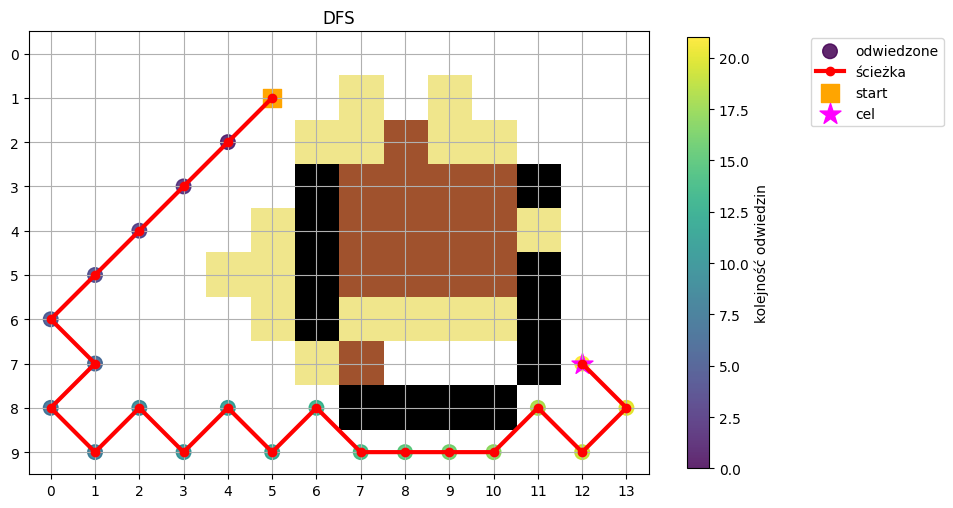

In [63]:
def dfs(start, goal):
    # Na stosie trzymamy pary (stan, rodzic). Rodzica zapisujemy dopiero wtedy,
    # gdy DFS faktycznie wchodzi do stanu – dzięki temu narysowana ścieżka
    # jest drogą, którą algorytm naprawdę przeszedł.
    stack = [(start, None)]
    visited = set()
    parent = {}
    visit_order = []

    while stack:
        current, current_parent = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                stack.append((neighbor, current))

    return None, visit_order


dfs_path, dfs_visited = dfs(start, goal)

print("DFS - długość ścieżki:", len(dfs_path) - 1)
print("DFS - odwiedzone stany:", len(dfs_visited))
print("DFS - ścieżka:", dfs_path)

draw_grid(dfs_path, dfs_visited, "DFS")

### BFS vs DFS

| Cecha | BFS | DFS |
|---|---|---|
| Struktura danych | kolejka | stos |
| Strategia | wszerz | w głąb |
| Najkrótsza ścieżka | tak, dla równych kosztów | nie |
| Kompletność | zwykle tak | zależy od przestrzeni |
| Pamięć | duża (cała „warstwa” w kolejce) | mała tylko w wersji bez zbioru odwiedzonych |
| Informacja o celu | nie | nie |

Ani BFS, ani DFS nie „wiedzą”, **w którą stronę znajduje się cel**.


# 5. Heurystyka

Heurystyka to funkcja, która próbuje oszacować:

> „Jak daleko jestem od celu?”

Zapisujemy ją jako:

$$
h(n)
$$

gdzie `n` jest aktualnym stanem.

Dobra heurystyka:
- jest szybka do policzenia,
- koreluje z rzeczywistym kosztem dojścia do celu,
- pomaga ograniczyć liczbę analizowanych stanów.

## Odległość Manhattan

Dla ruchów góra/dół/lewo/prawo:

$$
h(n) = |x_n - x_g| + |y_n - y_g|
$$


In [64]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def euclidean(a, b):
    return math.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)


examples = [(0, 0), (4, 6), (7, 10), (9, 12)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan(state, goal), 2),
        "Euclidean =", round(euclidean(state, goal), 2)
    )

(0, 0) Manhattan = 19 Euclidean = 13.89
(4, 6) Manhattan = 9 Euclidean = 6.71
(7, 10) Manhattan = 2 Euclidean = 2.0
(9, 12) Manhattan = 2 Euclidean = 2.0



### Heurystyka nie musi być idealna

Heurystyka nie rozwiązuje problemu.

Może nawet „nie widzieć” przeszkód.

Dla przykładu odległość Manhattan może wskazywać, że cel jest blisko, mimo że między stanem a celem znajduje się ściana.

Jej rolą jest **ukierunkowanie wyszukiwania**.



# 6. Greedy Best-First Search

Zanim przejdziemy do A*, zobaczmy prostszy algorytm.

Greedy Best-First Search wybiera stan z najmniejszą wartością:

$$
h(n)
$$

Czyli pyta wyłącznie:

> „Który stan wygląda na najbliższy celu?”

Nie bierze pod uwagę kosztu już przebytej drogi.


Greedy - długość ścieżki: 9
Greedy - odwiedzone stany: 13


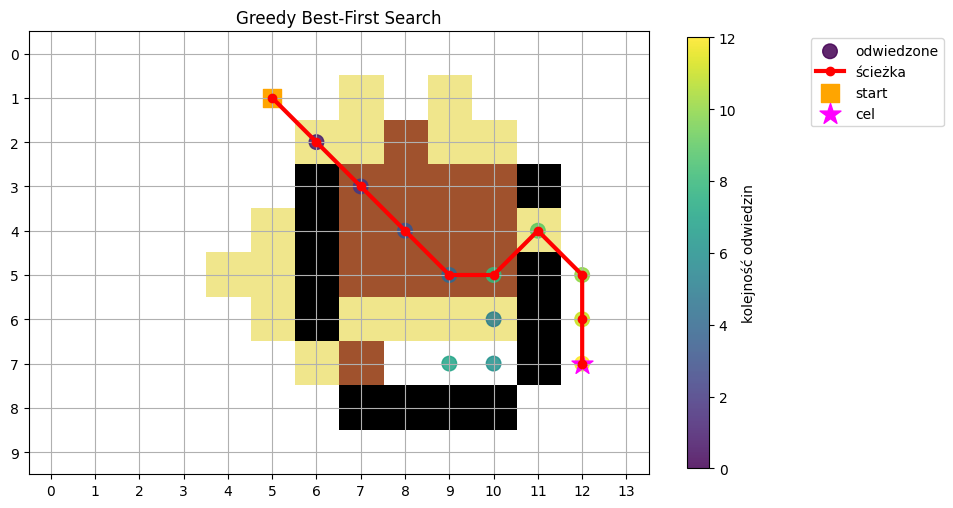

In [65]:
def greedy_best_first(start, goal):
    # W kopcu trzymamy (h, stan, rodzic) – rodzica zapisujemy przy zdjęciu z kopca,
    # tak jak w DFS.
    heap = []
    heapq.heappush(heap, (manhattan(start, goal), start, None))

    visited = set()
    parent = {}
    visit_order = []

    while heap:
        _, current, current_parent = heapq.heappop(heap)

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                heapq.heappush(
                    heap,
                    (manhattan(neighbor, goal), neighbor, current)
                )

    return None, visit_order


greedy_path, greedy_visited = greedy_best_first(start, goal)

print("Greedy - długość ścieżki:", len(greedy_path) - 1)
print("Greedy - odwiedzone stany:", len(greedy_visited))

draw_grid(greedy_path, greedy_visited, "Greedy Best-First Search")


# 7. A*

A* łączy dwie informacje.

## Koszt od startu

$$
g(n)
$$

czyli rzeczywisty koszt dojścia od startu do aktualnego stanu.

## Szacowany koszt do celu

$$
h(n)
$$

## Funkcja oceny

$$
f(n) = g(n) + h(n)
$$

A* wybiera stan o najmniejszej wartości `f(n)`.

Można to interpretować tak:

> „Szukam rozwiązania, które jest jednocześnie tanie do tej pory i wygląda obiecująco na przyszłość.”


A* - koszt ścieżki: 12.66
A* - liczba kroków: 11
A* - odwiedzone stany: 19
A* - ścieżka: [(1, 5), (1, 6), (0, 7), (0, 8), (0, 9), (1, 10), (2, 11), (3, 12), (4, 12), (5, 12), (6, 12), (7, 12)]


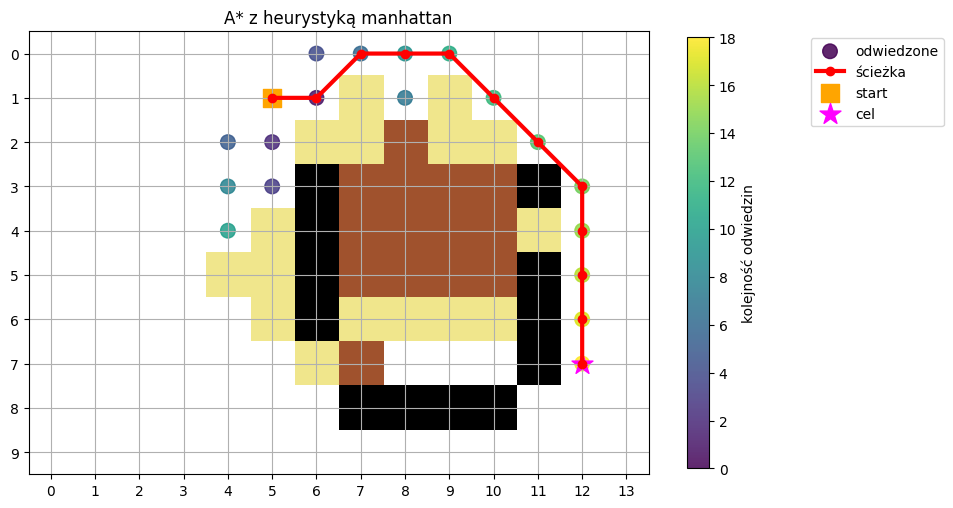

In [66]:
def astar(start, goal, heuristic=None):
    #h=M+(sqrt2-1)m - Octile distance
    if heuristic is None:
        def heuristic(a, b):
            dr, dc = abs(a[0] - b[0]), abs(a[1] - b[1])
            return max(dr, dc) + (math.sqrt(2) - 1) * min(dr, dc)

    open_heap = [(heuristic(start, goal), 0, start)]
    g_score = {start: 0.0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current_g, current = heapq.heappop(open_heap)

        if current_g > g_score.get(current, float("inf")):
            continue
        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            r1, c1 = current
            r2, c2 = neighbor
            terrain_cost = COST[grid[r2][c2]]
            diagonal_factor = math.sqrt(2) if r1 != r2 and c1 != c2 else 1.0
            step_cost = terrain_cost * diagonal_factor
            tentative_g = g_score[current] + step_cost

            if tentative_g < g_score.get(neighbor, float("inf")):
                g_score[neighbor] = tentative_g
                parent[neighbor] = current
                heapq.heappush(
                    open_heap,
                    (tentative_g + heuristic(neighbor, goal), tentative_g, neighbor)
                )

    return None, visit_order, float("inf")

astar_path, astar_visited, astar_cost = astar(start, goal, manhattan)

print("A* - koszt ścieżki:", round(astar_cost, 2))
print("A* - liczba kroków:", len(astar_path) - 1)
print("A* - odwiedzone stany:", len(astar_visited))
print("A* - ścieżka:", astar_path)

draw_grid(astar_path, astar_visited, "A* z heurystyką manhattan")


# 8. Porównanie algorytmów

Sprawdźmy:
- długość znalezionej ścieżki,
- liczbę odwiedzonych stanów.


In [67]:
results = [
    ("BFS", len(bfs_path) - 1, calculate_path_cost(bfs_path), len(bfs_visited)),
    ("DFS", len(dfs_path) - 1, calculate_path_cost(dfs_path), len(dfs_visited)),
    ("Greedy", len(greedy_path) - 1, calculate_path_cost(greedy_path), len(greedy_visited)),
    ("A*", len(astar_path) - 1, astar_cost, len(astar_visited)),
]

print(f"{'Algorytm':<12} {'Liczba kroków':<16} {'Koszt ścieżki':<18} {'Odwiedzone stany'}")
print("-" * 68)

for name, path_len, path_cost, visited_count in results:
    print(f"{name:<12} {path_len:<16} {path_cost:<18.2f} {visited_count}")

Algorytm     Liczba kroków    Koszt ścieżki      Odwiedzone stany
--------------------------------------------------------------------
BFS          9                23.97              119
DFS          21               28.46              22
Greedy       9                38.11              13
A*           11               12.66              19



## Interpretacja

Typowy wzorzec:

- **BFS** – znajduje drogę optymalną, ale może analizować wiele stanów,
- **DFS** – może szybko znaleźć rozwiązanie, ale nie musi być ono najlepsze,
- **Greedy** – mocno kieruje się ku celowi, ale może podjąć złą lokalną decyzję,
- **A\*** – łączy koszt dotychczasowy i heurystykę.

A* jest jednym z najważniejszych klasycznych algorytmów wyszukiwania w AI.


# 9. Co oznacza „dobra heurystyka”?

Dla A* szczególnie ważne jest pojęcie heurystyki **dopuszczalnej**.

Heurystyka jest dopuszczalna, jeśli nigdy nie przeszacowuje rzeczywistego kosztu dojścia do celu:

$$
h(n) \leq h^*(n)
$$

gdzie:

- $h(n)$ – nasza heurystyka,
- $h^*(n)$ – rzeczywisty minimalny koszt dojścia do celu.

Dla ruchów tylko:
- góra,
- dół,
- lewo,
- prawo,

odległość Manhattan jest naturalną heurystyką.

**Uwaga:** implementacja A* z tego notatnika (ze zbiorem `closed`, bez ponownego otwierania stanów) gwarantuje optymalność dla heurystyki **spójnej**:

$$
h(n) \leq c(n, n') + h(n')
$$

dla każdego sąsiada $n'$ stanu $n$. Każda heurystyka spójna jest dopuszczalna. Odległość Manhattan i odległość euklidesowa na naszej siatce są spójne.

In [68]:

astar_euclidean_path, astar_euclidean_visited, euklid_cost = astar(
    start,
    goal,
    heuristic=euclidean
)

print("A* Manhattan - odwiedzone stany:", len(astar_visited))
print("A* Euclidean - odwiedzone stany:", len(astar_euclidean_visited))


A* Manhattan - odwiedzone stany: 19
A* Euclidean - odwiedzone stany: 26



# 10. Eksperyment: A* bez heurystyki

Co się stanie, jeśli:

$$
h(n) = 0
$$

Wtedy:

$$
f(n) = g(n)
$$

A* zachowuje się wtedy jak algorytm Dijkstry.

Przy jednakowych kosztach przejść jego zachowanie jest bardzo zbliżone do BFS.


In [69]:

def zero_heuristic(a, b):
    return 0


path_h0, visited_h0, h0_cost = astar(
    start,
    goal,
    heuristic=zero_heuristic
)

print("A* z h=0 - odwiedzone stany:", len(visited_h0))
print("BFS       - odwiedzone stany:", len(bfs_visited))


A* z h=0 - odwiedzone stany: 102
BFS       - odwiedzone stany: 119



# 11. Eksperyment: zbyt agresywna heurystyka

Spróbujmy:

$$
h'(n) = 3 \cdot h(n)
$$

Taka heurystyka może przeszacowywać rzeczywisty koszt.

Wtedy A* może odwiedzać mniej stanów, ale traci gwarancję optymalności.


Koszt: 20.313708498984763
Odwiedzone stany: 13


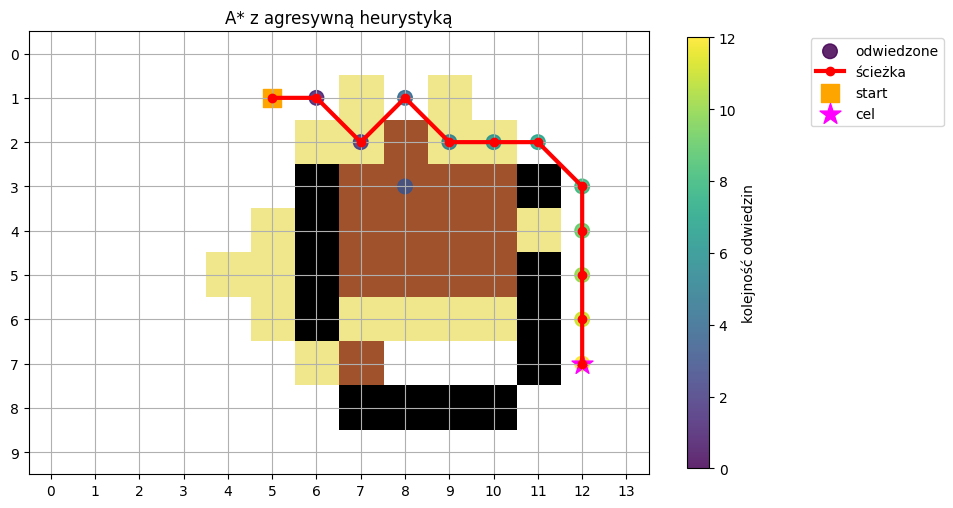

In [70]:

def aggressive_heuristic(a, b):
    return 3 * manhattan(a, b)


aggressive_path, aggressive_visited, aggressive_cost = astar(
    start,
    goal,
    heuristic=aggressive_heuristic
)

print("Koszt:", aggressive_cost)
print("Odwiedzone stany:", len(aggressive_visited))

draw_grid(
    aggressive_path,
    aggressive_visited,
    "A* z agresywną heurystyką"
)


In [71]:
#zadanie 3, 4, 5

def my_heuristic(a, b):
  return math.sqrt((a[0] - b[0])**2) + abs(a[1] - b[1])

def czebyszewa(a,b):
  return max(abs(a[0]-b[0]), abs(a[1]-b[1]))

astar_my_path, astar_my_visited, my_cost = astar(
    start,
    goal,
    heuristic=my_heuristic
)

astar_czeb_path, astar_czeb_visited, czeb_cost = astar(
    start,
    goal,
    heuristic=czebyszewa
)

astar_octile_path, astar_octile_visited, astar_octile_cost = astar(
    start,
    goal
)

print("A* My heuristic - odwiedzone stany:", len(astar_my_visited), "  path: ", len(astar_my_path), "  cost: ", my_cost)
print("A* Odl Czebyszewa - odwiedzone stany:", len(astar_czeb_visited), "  path: ", len(astar_czeb_path), "  cost: ", czeb_cost)
print("A* Manhattan - odwiedzone stany:", len(astar_visited), "  path: ", len(astar_path), "  cost: ", astar_cost)
print("A* Euclidean - odwiedzone stany:", len(astar_euclidean_visited), "  path: ", len(astar_euclidean_path), "  cost: ", euklid_cost)
print("A* z h=0 - odwiedzone stany:", len(visited_h0), "  path: ", len(path_h0), "  cost: ", h0_cost)
print("A* Octile Distance - odwiedzone stany:", len(astar_octile_visited), "  path: ", len(astar_octile_path), "  cost: ", astar_octile_cost)


'''
Wszystkie warianty algorytmu A* znalazły ścieżkę o tej samej długości i koszcie
Odległość Czebyszewa odwiedziła 31 stanów, euklidesowa 26, Octile Distance odwiedziła 25 stanów, uzyskując ten sam koszt drogi.
W tym przypadku Octile Distance okazała się najskuteczniejsza spośród tych trzech heurystyk.
Manhattan odwiedziła tylko 19 stanów, ale przy ruchach diagonalnych o koszcie sqrt{2} nie gwarantuje znalezienia optymalnej drogi
My heuristic działa tak samo jak Mahattan
'''



A* My heuristic - odwiedzone stany: 19   path:  12   cost:  12.65685424949238
A* Odl Czebyszewa - odwiedzone stany: 31   path:  12   cost:  12.65685424949238
A* Manhattan - odwiedzone stany: 19   path:  12   cost:  12.65685424949238
A* Euclidean - odwiedzone stany: 26   path:  12   cost:  12.65685424949238
A* z h=0 - odwiedzone stany: 102   path:  12   cost:  12.65685424949238
A* Octile Distance - odwiedzone stany: 25   path:  12   cost:  12.65685424949238


'\nWszystkie warianty algorytmu A* znalazły ścieżkę o tej samej długości i koszcie\nOdległość Czebyszewa odwiedziła 31 stanów, euklidesowa 26, Octile Distance odwiedziła 25 stanów, uzyskując ten sam koszt drogi. \nW tym przypadku Octile Distance okazała się najskuteczniejsza spośród tych trzech heurystyk. \nManhattan odwiedziła tylko 19 stanów, ale przy ruchach diagonalnych o koszcie sqrt{2} nie gwarantuje znalezienia optymalnej drogi\nMy heuristic działa tak samo jak Mahattan\n'


# 12. Zadania dla studentów

## Zadanie 1 — zmiana kolejności DFS

W funkcji `get_neighbors()` zmień kolejność ruchów.

Sprawdź:
- czy DFS znajdzie inną ścieżkę,
- czy zmieni się liczba odwiedzonych stanów.

Wyjaśnij dlaczego.

## Odpowiedź:
Tak, DFS znalazł inną ścieżkę i zmieniła się liczba odwiedzonych stanów. DFS wykorzystuje stos LIFO, dlatego zmiana kolejności sąsiadów wpływa na kierunek przeszukiwania.

---

## Zadanie 2 — nowa mapa

Zmodyfikuj przeszkody w `grid`.

Stwórz mapę, na której:
- BFS odwiedzi dużo stanów,
- A* odwiedzi wyraźnie mniej stanów.


## Zadanie 3 — własna heurystyka

Napisz heurystykę:

```python
def my_heuristic(a, b):
    ...
```

Porównaj ją z:
- Manhattan,
- Euclidean,
- `h(n)=0`.

---

## Zadanie 4 — ruch po przekątnej

Dodaj ruchy:

```text
↖ ↑ ↗
←   →
↙ ↓ ↘
```

Odpowiedz:

1. Czy Manhattan nadal jest najlepszym wyborem?

Nie. Przy ruchach diagonalnych o koszcie 1 Manhattan może przeszacowywać koszt dojścia do celu,
przez co A* traci gwarancję optymalności, bo jest zbyt agresywna heurystyka.   

2. Jaką heurystykę zastosować?

Odległość Czebyszewa, gdy ruchy poziome, pionowe i diagonalne mają jednakowy koszt, bo oblicza, ile maksymalnie ruchów musisz wykonać w jednej z osi: h(n)=max(dx,dy)

3. Co się zmieni, jeśli koszt ruchu po przekątnej będzie równy $\sqrt{2}$?

Wtedy odpowiednia jest heurystyka Octile Distance: h(n)=M+($\sqrt{2}$-1)m
Uwzględnia ona koszt ruchów diagonalnych i prostych, dlatego lepiej pasuje do takiego modelu ruchu niż heurystyka Czebyszewa.

Odległość euklidesowa również jest dopuszczalna w tym modelu, ponieważ nie przeszacowuje kosztu dojścia.

---

## Zadanie 5 — przeszkody z różnym kosztem

Załóż, że wejście na:
- zwykłe pole kosztuje `1`,
- piasek kosztuje `3`,
- bagno kosztuje `5`.

Zmodyfikuj A*, aby uwzględniał różne koszty przejść.

Czy BFS nadal gwarantuje znalezienie najtańszej ścieżki?

## Odpowiedź
g(n) jest sumą kosztów przejść od startu do aktualnego stanu, a nie samą liczbą kroków

BFS nie gwarantuje najtańszej ścieżki przy różnych kosztach pól, ponieważ minimalizuje liczbę kroków, a nie ich łączny koszt

---

## Zadanie 6 — pytanie koncepcyjne

Wyjaśnij własnymi słowami różnicę między:

$$
g(n)
$$

a

$$
h(n)
$$

w algorytmie A*.

## Odpowiedź
g(n) - to rzeczywisty koszt drogi od stanu początkowego do stanu n

A h(n) - szacowany koszt, jaki pozostał od stanu n do celu

dla wyliczania h(n) istnieją różne metody

w algorytmie A* wykorzystuje się f(n)=g(n)+h(n) dla wyboru najlepszej opcji

# 13. Zadanie rozszerzone — 8-puzzle

Rozważ układankę:

```text
_ 2 4
3 6 5
7 1 8
```

Stan można zapisać jako:

```python
(0, 2, 4,
 3, 6, 5,
 7, 1, 8)
```

gdzie `0` oznacza puste pole.

Stan docelowy:

```python
(1, 2, 3,
 4, 5, 6,
 7, 8, 0)
```

### Zadanie

Zaimplementuj A* dla 8-puzzle.

Jako heurystykę wykorzystaj:

> sumę odległości Manhattan każdego kafelka od jego pozycji docelowej.

To klasyczny przykład problemu przeszukiwania przestrzeni stanów.

In [72]:
# Miejsce na rozwiązanie zadania 8-puzzle.

# TODO:
# 1. napisz funkcję generującą sąsiadów,
# 2. napisz heurystykę Manhattan,
# 3. wykorzystaj A*.

import heapq

#start_puzzle = (
#    0, 2, 4,
#    3, 6, 5,
#    7, 1, 8
#)

start_puzzle = (8, 6, 7, 2, 5, 4, 3, 0, 1)

goal_puzzle = (
    1, 2, 3,
    4, 5, 6,
    7, 8, 0
)

#(0,-1)lewo  (1, 0)dół (-1, 0)góra (0, 1)prawo

def puzzle_neighbours(state):
  zero = state.index(0)
  row, col = divmod(zero, 3)

  for dr, dc in [(-1,0), (1,0), (0,-1), (0,1)]:
    nr = row+dr
    nc = col+dc

    if 0<=nr<3 and 0<=nc<3:
      new_ind = nr*3+nc
      list_state = list(state)
      list_state[new_ind], list_state[zero] = list_state[zero], list_state[new_ind]
      yield tuple(list_state)


def heur_manh(state, goal=goal_puzzle):
  goal_positions = {tile: i for i, tile in enumerate(goal)}
  distance = 0

  for i, tile in enumerate(state):
    if tile==0:
      continue

    goal_i = goal_positions[tile]
    row_g, col_g = divmod(goal_i,3)
    row_s, col_s = divmod(i,3)

    distance+=abs(row_g-row_s)+abs(col_g-col_s)

  return distance


def astar_puzzle(start, goal):
  # function return Path, len(expanded), cost
  #(f,g,state)
  frontier = [(heur_manh(start, goal), 0, start)]
  came_from = {start: None}
  g_score = {start: 0}
  expanded = set()

  while frontier:
    f_score, current_cost, current = heapq.heappop(frontier)

    if current in expanded or current_cost!=g_score.get(current):
      continue

    if current == goal:
      path = []
      state = current
      while state is not None:
        path.append(state)
        state = came_from[state]
      path.reverse()
      return path, len(expanded), current_cost

    expanded.add(current)

    for neighbour in puzzle_neighbours(current):
      hepothetical_g = current_cost+1

      if hepothetical_g<g_score.get(neighbour, float("inf")):
        g_score[neighbour]=hepothetical_g
        came_from[neighbour]=current
        f=hepothetical_g+heur_manh(neighbour,goal)
        heapq.heappush(frontier, (f, hepothetical_g, neighbour))

  return None, len(expanded), float("inf")

path_puzzle, puzzle_expanded, puzzle_cost = astar_puzzle(start_puzzle, goal_puzzle)

if path_puzzle is None:
    print("Nie znaleziono rozwiązania.")
else:
    print("Liczba ruchów:", puzzle_cost)
    print("Liczba stanów na ścieżce:", len(path_puzzle))
    print("Liczba rozwiniętych stanów:", puzzle_expanded)
    print("Heurystyka Manhattan dla startu:", heur_manh(start_puzzle))

    for step, state in enumerate(path_puzzle):
        print(f"\nKrok {step}:")
        for row in range(3):
            print(state[row*3 : (row+1)*3])



Liczba ruchów: 31
Liczba stanów na ścieżce: 32
Liczba rozwiniętych stanów: 21197
Heurystyka Manhattan dla startu: 21

Krok 0:
(8, 6, 7)
(2, 5, 4)
(3, 0, 1)

Krok 1:
(8, 6, 7)
(2, 0, 4)
(3, 5, 1)

Krok 2:
(8, 0, 7)
(2, 6, 4)
(3, 5, 1)

Krok 3:
(8, 7, 0)
(2, 6, 4)
(3, 5, 1)

Krok 4:
(8, 7, 4)
(2, 6, 0)
(3, 5, 1)

Krok 5:
(8, 7, 4)
(2, 0, 6)
(3, 5, 1)

Krok 6:
(8, 7, 4)
(0, 2, 6)
(3, 5, 1)

Krok 7:
(8, 7, 4)
(3, 2, 6)
(0, 5, 1)

Krok 8:
(8, 7, 4)
(3, 2, 6)
(5, 0, 1)

Krok 9:
(8, 7, 4)
(3, 2, 6)
(5, 1, 0)

Krok 10:
(8, 7, 4)
(3, 2, 0)
(5, 1, 6)

Krok 11:
(8, 7, 4)
(3, 0, 2)
(5, 1, 6)

Krok 12:
(8, 7, 4)
(0, 3, 2)
(5, 1, 6)

Krok 13:
(0, 7, 4)
(8, 3, 2)
(5, 1, 6)

Krok 14:
(7, 0, 4)
(8, 3, 2)
(5, 1, 6)

Krok 15:
(7, 4, 0)
(8, 3, 2)
(5, 1, 6)

Krok 16:
(7, 4, 2)
(8, 3, 0)
(5, 1, 6)

Krok 17:
(7, 4, 2)
(8, 0, 3)
(5, 1, 6)

Krok 18:
(7, 4, 2)
(8, 1, 3)
(5, 0, 6)

Krok 19:
(7, 4, 2)
(8, 1, 3)
(0, 5, 6)

Krok 20:
(7, 4, 2)
(0, 1, 3)
(8, 5, 6)

Krok 21:
(0, 4, 2)
(7, 1, 3)
(8, 5, 6)

Krok 22:
(4,

# 14. Podsumowanie

Najważniejsze idee:

### Przestrzeń stanów
Problem AI można traktować jako zbiór stanów połączonych możliwymi akcjami.

### BFS
Przeszukuje wszerz i dla jednakowych kosztów gwarantuje najkrótszą ścieżkę.

### DFS
Przeszukuje w głąb i nie gwarantuje najlepszego rozwiązania. W wersji bez zapamiętywania odwiedzonych stanów potrzebuje znacznie mniej pamięci niż BFS.

### Heurystyka
Dostarcza dodatkowej wiedzy o tym, które stany wyglądają obiecująco.

### A*
Łączy:

$$
g(n)
$$

oraz

$$
h(n)
$$

w funkcji:

$$
f(n)=g(n)+h(n)
$$

Dzięki temu może znajdować optymalne rozwiązania znacznie bardziej efektywnie niż algorytmy niepoinformowane.


# 15. Pytania kontrolne

1. Co jest stanem w problemie wyszukiwania drogi?
2. Czym różni się BFS od DFS?
3. Dlaczego BFS może potrzebować dużo pamięci?
4. Co oznacza $g(n)$?
5. Co oznacza $h(n)$?
6. Co oznacza $f(n)$?
7. Dlaczego heurystyka może przyspieszyć wyszukiwanie?
8. Co oznacza, że heurystyka jest dopuszczalna?
9. Co się stanie w A*, gdy $h(n)=0$?
10. Czy A* zawsze jest szybszy od BFS?
